In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df_full = pd.read_csv('autoinsurance_churn.csv')
print(df_full.shape)

(1680909, 22)


## **Data Understanding**

In [ ]:
df_full.head()

,individual_id,address_id,curr_ann_amt,days_tenure,cust_orig_date,age_in_years,date_of_birth,latitude,longitude,city,...,income,has_children,length_of_residence,marital_status,home_market_value,home_owner,college_degree,good_credit,acct_suspd_date,Churn
0,2.213000e+11,5.213000e+11,818.877997,1454.0,2018-12-09,44,1978-06-23,32.578829,-96.305006,Kaufman,...,22500.0,1.0,15.0,Married,50000 - 74999,1.0,1.0,1.0,NaN,0
1,2.213001e+11,5.213001e+11,974.199182,1795.0,2018-01-02,72,1950-05-30,32.732209,-97.000893,Grand Prairie,...,27500.0,0.0,2.0,Single,50000 - 74999,1.0,0.0,0.0,NaN,0
2,2.213007e+11,5.213002e+11,967.375112,4818.0,2009-09-23,55,1967-07-07,32.819777,-96.846938,Dallas,...,42500.0,0.0,10.0,Married,75000 - 99999,1.0,0.0,0.0,NaN,0
3,2.213016e+11,5.213006e+11,992.409561,130.0,2022-07-25,53,1969-05-25,32.684065,-97.162180,Arlington,...,125000.0,1.0,6.0,Married,175000 - 199999,1.0,0.0,1.0,2021-12-22,1
4,2.213016e+11,5.213006e+11,784.633494,5896.0,2006-10-11,50,1972-09-25,32.751398,-97.376745,Fort Worth,...,87500.0,1.0,4.0,Married,225000 - 249999,1.0,1.0,1.0,NaN,0


In [ ]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1680909 entries, 0 to 1680908
Data columns (total 22 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   individual_id        1680909 non-null  float64
 1   address_id           1680909 non-null  float64
 2   curr_ann_amt         1680909 non-null  float64
 3   days_tenure          1680909 non-null  float64
 4   cust_orig_date       1680909 non-null  object 
 5   age_in_years         1680909 non-null  int64  
 6   date_of_birth        1680909 non-null  object 
 7   latitude             1427190 non-null  float64
 8   longitude            1427190 non-null  float64
 9   city                 1668842 non-null  object 
 10  state                1680909 non-null  object 
 11  county               1668842 non-null  object 
 12  income               1680909 non-null  float64
 13  has_children         1680909 non-null  float64
 14  length_of_residence  1680909 non-null  float64
 15

In [ ]:
df_full.describe(include='object')

,cust_orig_date,date_of_birth,city,state,county,marital_status,home_market_value,acct_suspd_date
count,1680909,1680909,1668842,1680909,1668842,1680909,1588623,193456
unique,5244,1085,95,1,14,2,19,300
top,2005-09-11,1967-07-07,Dallas,TX,Dallas,Married,75000 - 99999,2022-08-14
freq,495114,142238,305939,1680909,623980,1048453,306463,713


In [ ]:
df_full['Churn'].value_counts()

,count
Churn,
0,1487453
1,193456


In [ ]:
df_full['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
0,88.490989
1,11.509011


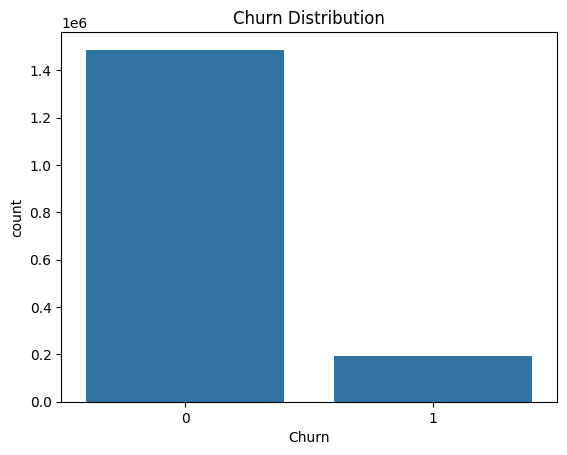

In [ ]:
sns.countplot(x='Churn', data=df_full)
plt.title('Churn Distribution')
plt.show()

In [ ]:
df_full.isnull().sum()

,0
individual_id,0
address_id,0
curr_ann_amt,0
days_tenure,0
cust_orig_date,0
age_in_years,0
date_of_birth,0
latitude,253719
longitude,253719
city,12067


In [ ]:
df_full.duplicated().sum()

np.int64(0)

In [ ]:
num_cols = df_full.select_dtypes(include='number').columns.tolist()
cat_cols = df_full.select_dtypes(include='object').columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['individual_id', 'address_id', 'curr_ann_amt', 'days_tenure', 'age_in_years', 'latitude', 'longitude', 'income', 'has_children', 'length_of_residence', 'home_owner', 'college_degree', 'good_credit', 'Churn']
Categorical: ['cust_orig_date', 'date_of_birth', 'city', 'state', 'county', 'marital_status', 'home_market_value', 'acct_suspd_date']


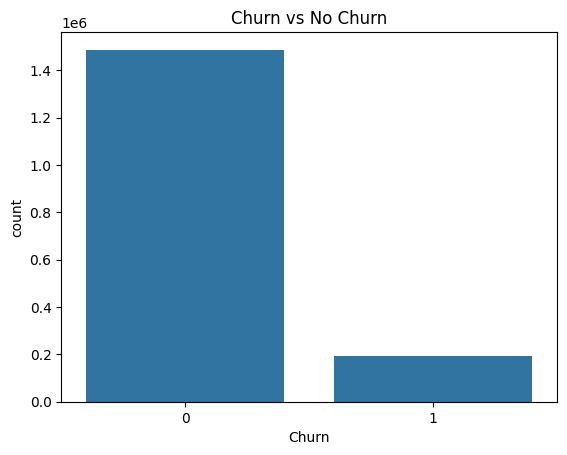

In [ ]:
sns.countplot(x='Churn', data=df_full)
plt.title('Churn vs No Churn')
plt.show()

In [ ]:
df_full.groupby('Churn')['acct_suspd_date'].apply(lambda x: x.notnull().mean())

,acct_suspd_date
Churn,
0,0.0
1,1.0


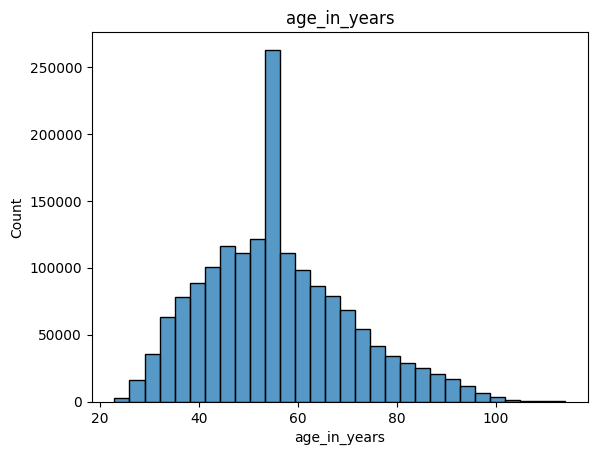

In [ ]:
cols = ['age_in_years']

for col in cols:
    sns.histplot(df_full[col], bins=30)
    plt.title(col)
    plt.show()

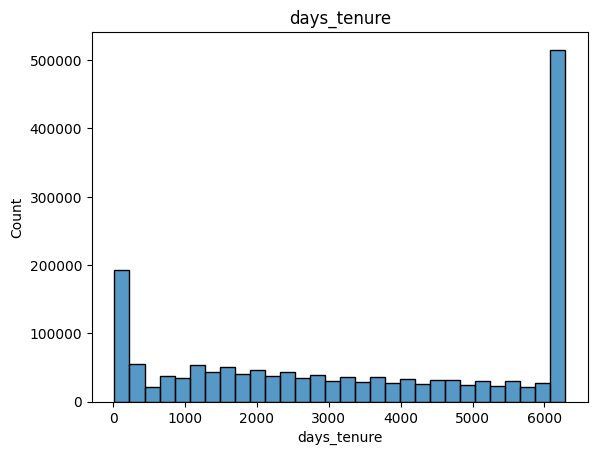

In [ ]:
cols = ['days_tenure']

for col in cols:
    sns.histplot(df_full[col], bins=30)
    plt.title(col)
    plt.show()

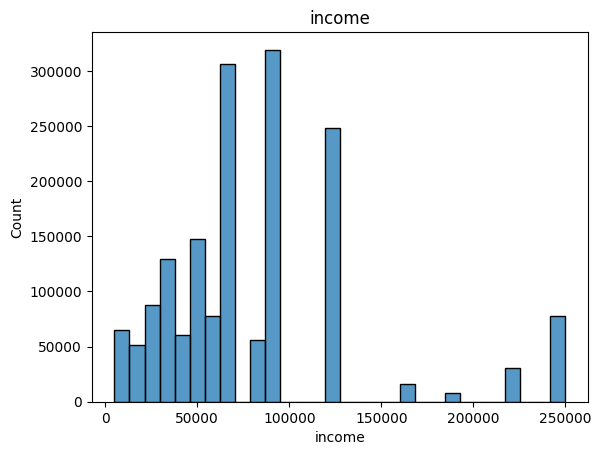

In [ ]:
cols = ['income']

for col in cols:
    sns.histplot(df_full[col], bins=30)
    plt.title(col)
    plt.show()

In [ ]:
for col in cat_cols:
    print(df_full.groupby(col)['Churn'].mean() * 100)
    print()

cust_orig_date
2005-09-11     6.972738
2005-09-13     7.207207
2005-09-14    50.000000
2005-09-15    13.636364
2005-09-16     8.633094
                ...    
2022-11-08    63.157895
2022-11-09    45.454545
2022-11-10    37.500000
2022-11-11    66.666667
2022-11-12     0.000000
Name: Churn, Length: 5244, dtype: float64

date_of_birth
1908-12-11     0.000000
1909-01-10     0.000000
1909-02-07     0.000000
1909-03-10     0.000000
1909-04-09     0.000000
                ...    
1999-02-17     7.142857
1999-03-19    16.279070
1999-04-19    13.333333
1999-05-19    20.000000
1999-06-19    14.285714
Name: Churn, Length: 1085, dtype: float64

city
Addison        12.371134
Aledo          11.817168
Allen          11.442374
Anna           11.924883
Argyle         12.069584
                 ...    
Valley View    10.500352
Waxahachie     11.110212
Weatherford    11.010516
Wilmer         11.889862
Wylie          12.243017
Name: Churn, Length: 95, dtype: float64

state
TX    11.509011
Name: Churn, d

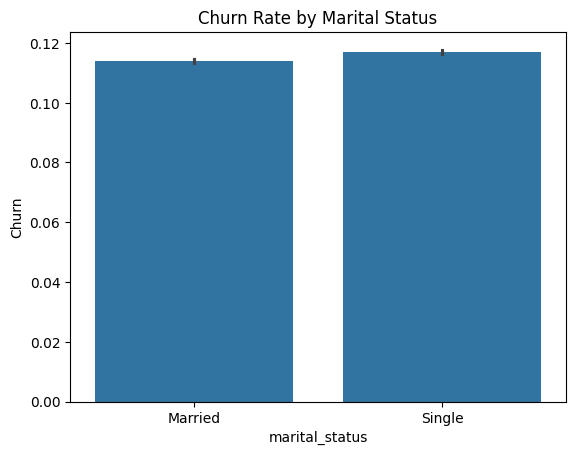

In [ ]:
sns.barplot(x='marital_status', y='Churn', data=df_full)
plt.title('Churn Rate by Marital Status')
plt.show()

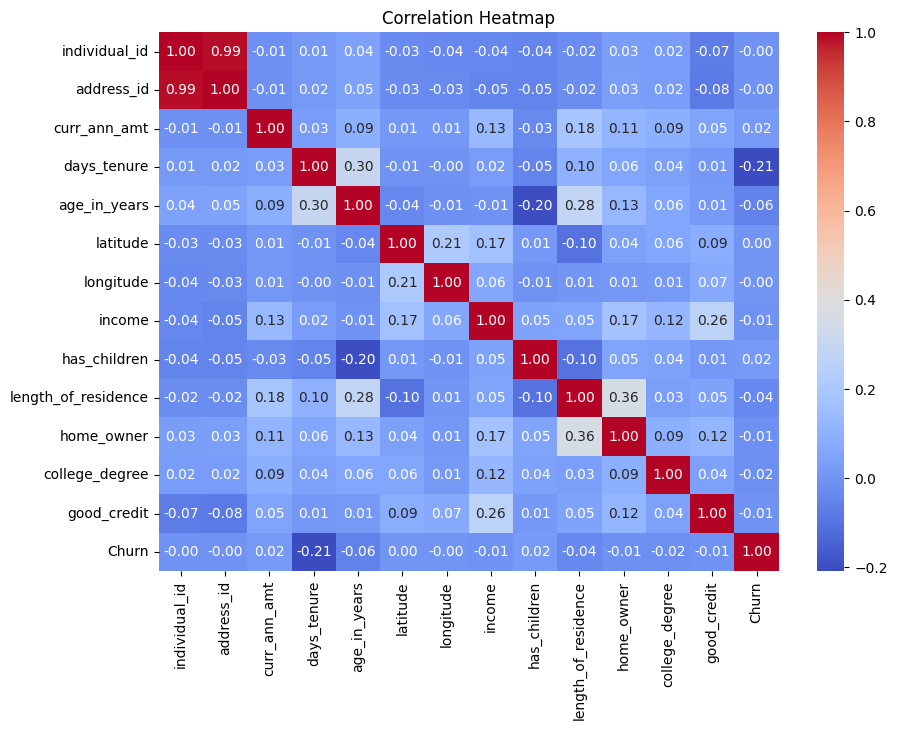

In [ ]:
plt.figure(figsize=(10,7))
sns.heatmap(df_full.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## **Data Preprocessing**

In [ ]:
drop_cols = ['individual_id', 'address_id',
             'date_of_birth', 'cust_orig_date',
             'acct_suspd_date',
             'latitude', 'longitude',
             'city', 'state', 'county']

df_full = df_full.drop(columns=drop_cols)
print(df_full.shape)
df_full.columns

(1680909, 12)


Index(['curr_ann_amt', 'days_tenure', 'age_in_years', 'income', 'has_children',
       'length_of_residence', 'marital_status', 'home_market_value',
       'home_owner', 'college_degree', 'good_credit', 'Churn'],
      dtype='object')

In [ ]:
print("Duplicates before:", df_full.duplicated().sum())
df_full = df_full.drop_duplicates()
print("Shape after:", df_full.shape)

Duplicates before: 0
Shape after: (1680909, 12)


In [ ]:
from sklearn.model_selection import train_test_split
X = df_full.drop('Churn', axis=1)
y = df_full['Churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(1344727, 11) (336182, 11)
0.11509027482901733 0.11508944559792017


## **FETAURE ENGINEERING**

In [ ]:

X_train['tenure_years'] = X_train['days_tenure'] / 365
X_test['tenure_years'] = X_test['days_tenure'] / 365

X_train['is_new_customer'] = (X_train['days_tenure'] < 365).astype(int)
X_test['is_new_customer'] = (X_test['days_tenure'] < 365).astype(int)

X_train.head()

,curr_ann_amt,days_tenure,age_in_years,income,has_children,length_of_residence,marital_status,home_market_value,home_owner,college_degree,good_credit,tenure_years,is_new_customer
267244,716.190264,679.0,30,37500.0,1.0,1.0,Single,50000 - 74999,1.0,0.0,1.0,1.860274,0
70393,665.048161,2810.0,55,70000.0,0.0,3.0,Single,175000 - 199999,1.0,1.0,1.0,7.698630,0
1094749,1068.758337,2549.0,64,87500.0,0.0,15.0,Single,100000 - 124999,1.0,1.0,1.0,6.983562,0
39537,731.384529,6291.0,54,87500.0,1.0,15.0,Single,125000 - 149999,1.0,1.0,1.0,17.235616,0
987354,564.254152,1160.0,34,42500.0,0.0,0.0,Single,NaN,0.0,0.0,1.0,3.178082,0


In [ ]:
X_train = X_train.drop(columns=['home_market_value'])
X_test = X_test.drop(columns=['home_market_value'])

In [ ]:
X_train_encoded = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test_encoded = pd.get_dummies(X_test, drop_first=True, dtype=int)
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Scaled training features shape:", X_train_scaled.shape)

Scaled training features shape: (1344727, 12)


### **Model Building**

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)
dt.fit(X_train_encoded, y_train)
dt_pred = dt.predict(X_test_encoded)

In [ ]:
print(lr_pred[:10])
print(dt_pred[:10])

[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]


## **MODEL EVALUATION**


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall   :", recall_score(y_test, lr_pred))
print("F1       :", f1_score(y_test, lr_pred))

Logistic Regression
Accuracy : 0.8509319356776984
Precision: 0.3795321760772816
Recall   : 0.46506939598356206
F1       : 0.4179693851478479


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.93      0.93      0.93    297491
           1       0.46      0.46      0.46     38691

    accuracy                           0.88    336182
   macro avg       0.70      0.69      0.69    336182
weighted avg       0.88      0.88      0.88    336182



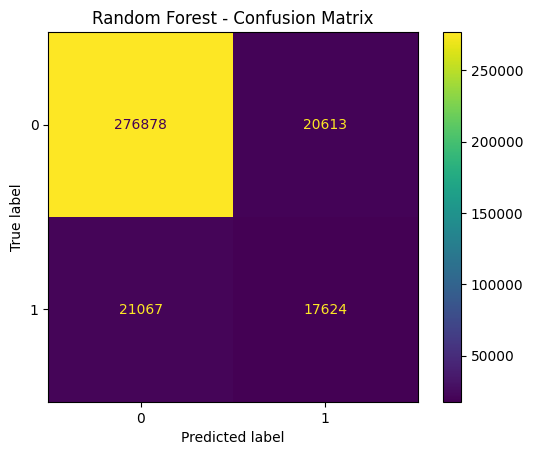

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title('Random Forest - Confusion Matrix')
plt.show()


In [ ]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, dt_pred), accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, dt_pred), precision_score(y_test, rf_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, dt_pred), recall_score(y_test, rf_pred)],
    'F1': [f1_score(y_test, lr_pred), f1_score(y_test, dt_pred), f1_score(y_test, rf_pred)]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.851,0.380,0.465,0.418
1,Decision Tree,0.876,0.460,0.454,0.457
2,Random Forest,0.876,0.461,0.456,0.458


## **Model Selection**

In [ ]:
X_train['marital_status'] = X_train['marital_status'].map({'Married': 0, 'Single': 1})
X_test['marital_status'] = X_test['marital_status'].map({'Married': 0, 'Single': 1})

X_train['marital_status'] = X_train['marital_status'].fillna(0)
X_test['marital_status'] = X_test['marital_status'].fillna(0)

In [ ]:
print(X_train.select_dtypes(exclude='number').columns.tolist())   # must be []
print(X_train.isnull().sum().sum())                               # must be 0

[]
0


In [ ]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced',
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_proba = rf.predict_proba(X_test)[:, 1]
print(rf_proba[:10].round(2))

[0.37 0.37 0.37 0.37 0.36 0.36 0.36 0.37 0.37 0.37]


In [ ]:
sample = X_test.head(10)

result = pd.DataFrame({
    'Actual': y_test.head(10).values,
    'Predicted': rf.predict(sample),
    'Churn_Probability': rf.predict_proba(sample)[:, 1].round(2)
})

result

,Actual,Predicted,Churn_Probability
0,1,0,0.37
1,0,0,0.37
2,1,0,0.37
3,0,0,0.37
4,0,0,0.36
5,0,0,0.36
6,0,0,0.36
7,0,0,0.37
8,0,0,0.37
9,0,0,0.37
